In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

In [4]:
!pip install scipy

In [5]:
np.random.seed(42)

a = 10
b = 2

Nmax = 19

x = np.arange(1, Nmax + 1)

theory = a + b * x
sigma = np.full(Nmax, 2.0)

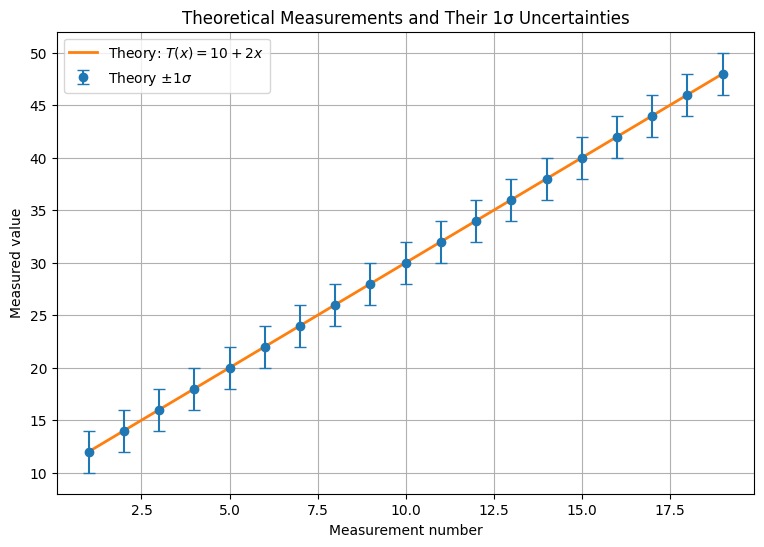

In [6]:
plt.figure(figsize=(9, 6))

plt.errorbar(
    x,
    theory,
    yerr=sigma,
    fmt='o',
    capsize=4,
    label=r'Theory $\pm1\sigma$'
)

plt.plot(
    x,
    theory,
    linewidth=2,
    label=r'Theory: $T(x)=10+2x$'
)

plt.xlabel('Measurement number')
plt.ylabel('Measured value')
plt.title('Theoretical Measurements and Their 1σ Uncertainties')
plt.legend()
plt.grid(True)

plt.show()

In [7]:
ndofs = [3, 7, 9, 15, 19]

example_samples = {}

for ndof in ndofs:
    example_samples[ndof] = [
        np.random.normal(
            theory[:ndof],
            sigma[:ndof]
        )
        for _ in range(5)
    ]
    

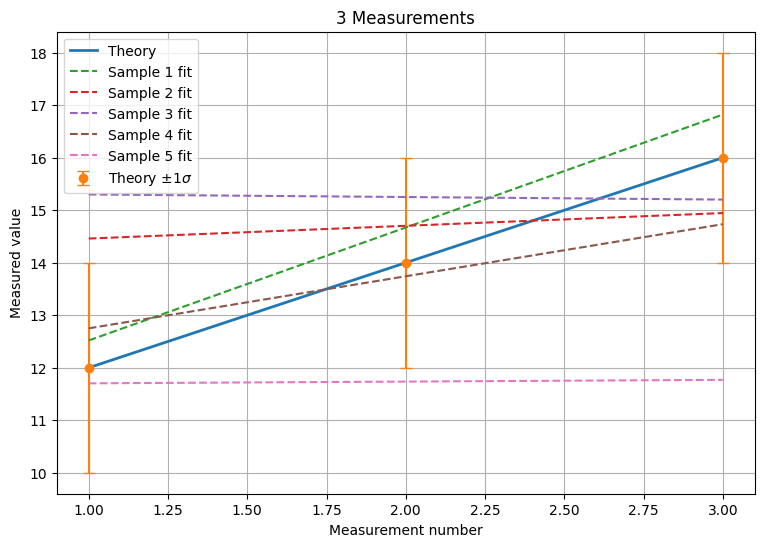

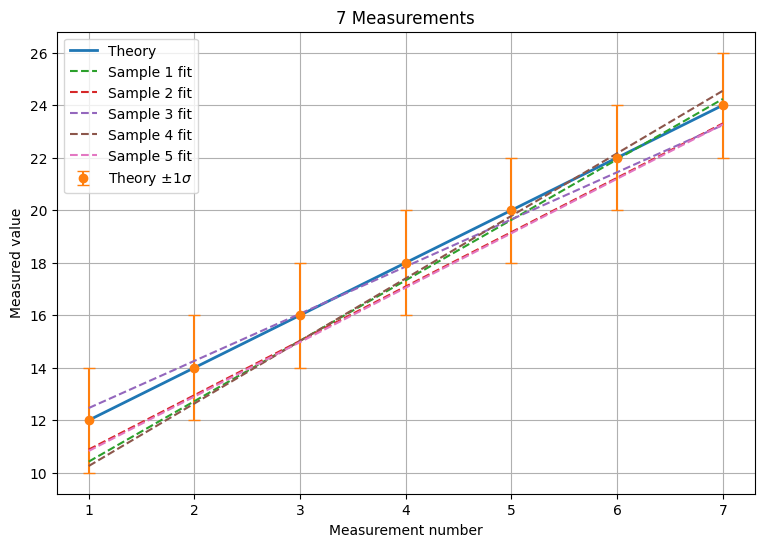

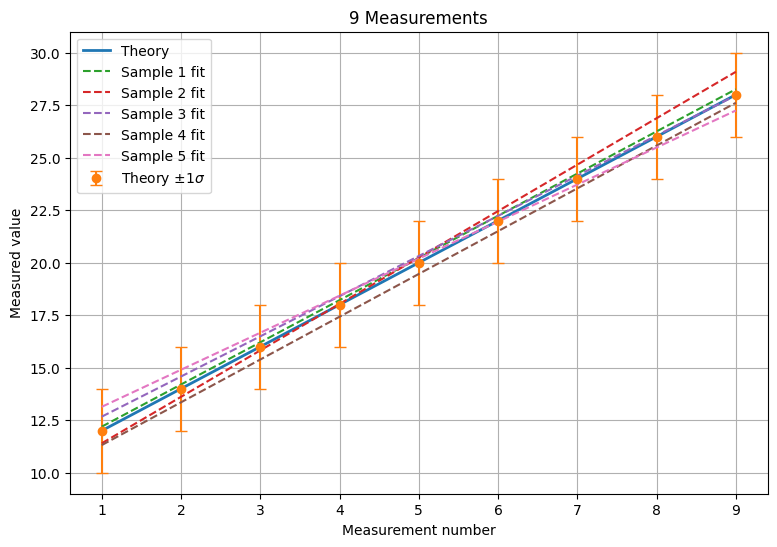

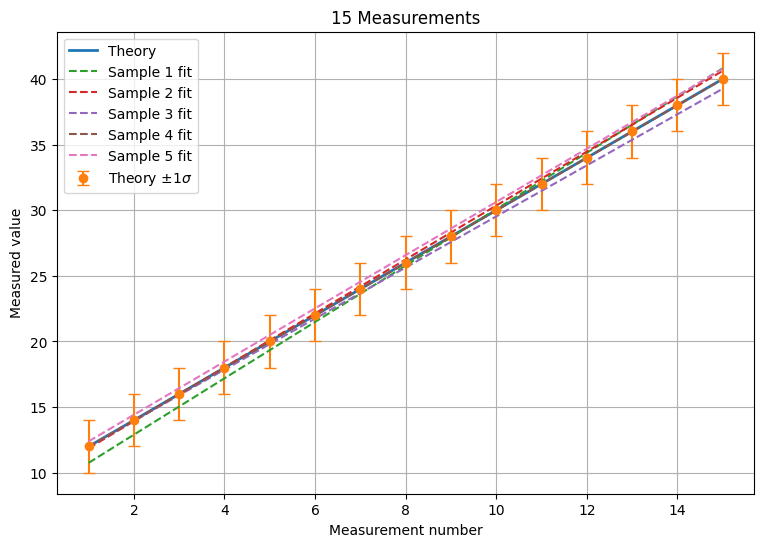

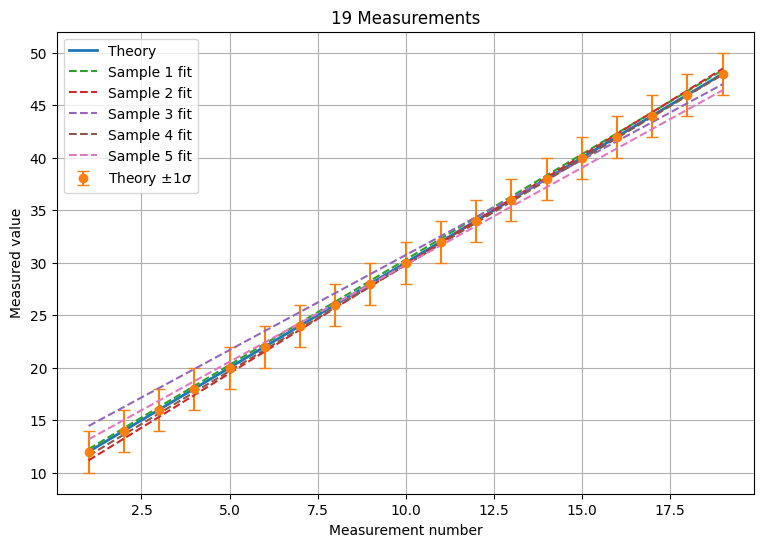

In [8]:
for ndof in ndofs:

    plt.figure(figsize=(9, 6))

    x_n = x[:ndof]
    theory_n = theory[:ndof]

    plt.plot(
        x_n,
        theory_n,
        linewidth=2,
        label='Theory'
    )

    plt.errorbar(
        x_n,
        theory_n,
        yerr=sigma[:ndof],
        fmt='o',
        capsize=4,
        label=r'Theory $\pm1\sigma$'
    )

    for i, sample in enumerate(example_samples[ndof], 1):

        fit = np.polyfit(x_n, sample, 1)

        fitted_line = (
            fit[0] * x_n + fit[1]
        )

        plt.plot(
            x_n,
            fitted_line,
            linestyle='--',
            label=f'Sample {i} fit'
        )

    plt.xlabel('Measurement number')
    plt.ylabel('Measured value')
    plt.title(f'{ndof} Measurements')
    plt.legend()
    plt.grid(True)

    plt.show()

In [9]:
Nexperiments = 1000

chi2_samples = {}

for ndof in ndofs:

    theory_n = theory[:ndof]
    sigma_n = sigma[:ndof]

    measurements = np.random.normal(
        loc=theory_n,
        scale=sigma_n,
        size=(Nexperiments, ndof)
    )

    chi2_values = np.sum(
        ((measurements - theory_n) / sigma_n) ** 2,
        axis=1
    )

    chi2_samples[ndof] = chi2_values

In [22]:
for ndof in ndofs:

    values = chi2_samples[ndof]

    mean = np.mean(values)
    std = np.std(values)

    expected_mean = ndof
    expected_std = np.sqrt(2 * ndof)

   

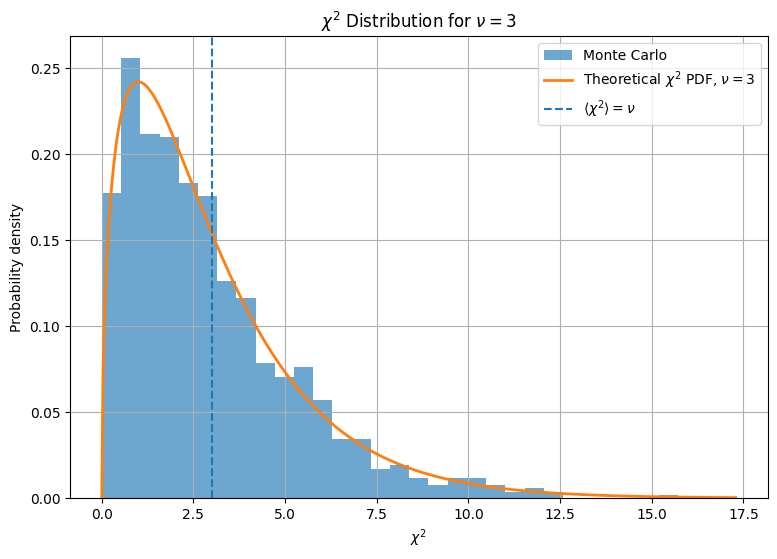

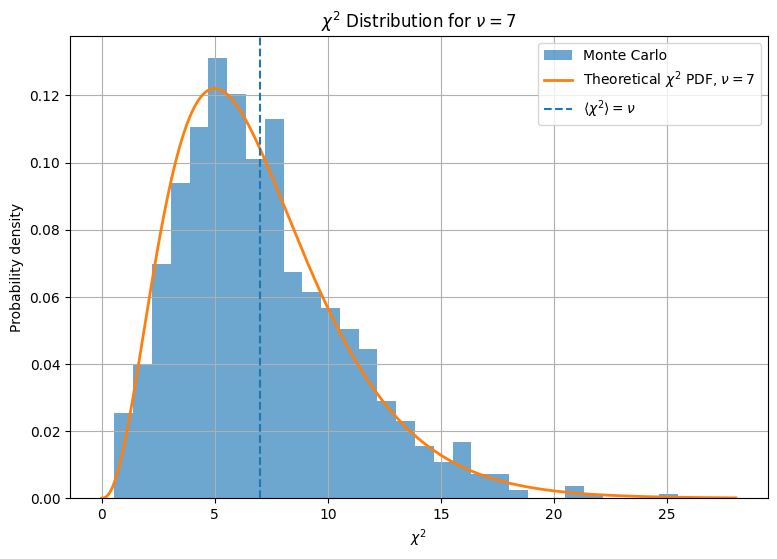

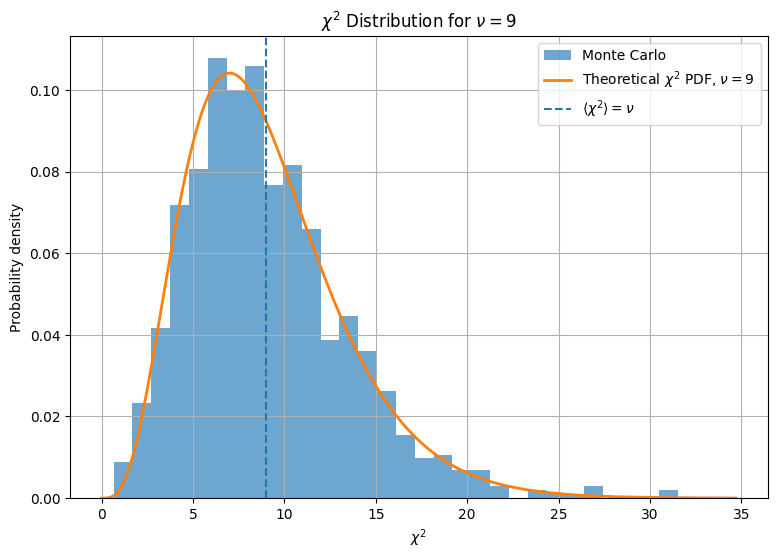

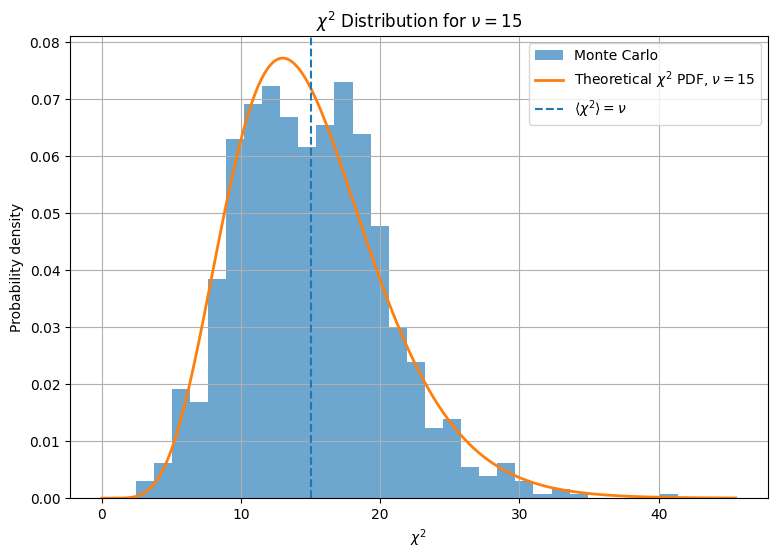

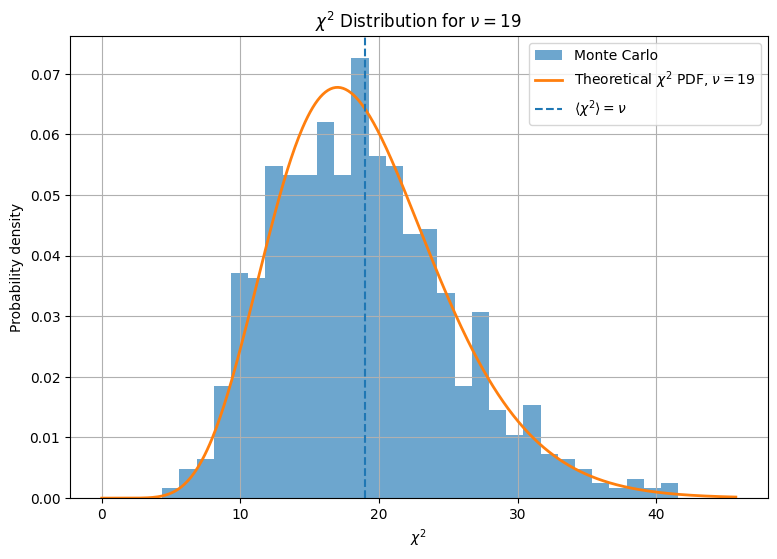

In [11]:
for ndof in ndofs:

    values = chi2_samples[ndof]

    plt.figure(figsize=(9, 6))

    plt.hist(
        values,
        bins=30,
        density=True,
        alpha=0.65,
        label='Monte Carlo'
    )

    x_pdf = np.linspace(
        0,
        max(values) * 1.1,
        500
    )

    plt.plot(
        x_pdf,
        chi2.pdf(x_pdf, ndof),
        linewidth=2,
        label=fr'Theoretical $\chi^2$ PDF, $\nu={ndof}$'
    )

    plt.axvline(
        ndof,
        linestyle='--',
        linewidth=1.5,
        label=r'$\langle\chi^2\rangle=\nu$'
    )

    plt.xlabel(r'$\chi^2$')
    plt.ylabel('Probability density')
    plt.title(
        fr'$\chi^2$ Distribution for $\nu={ndof}$'
    )
    plt.legend()
    plt.grid(True)

    plt.show()

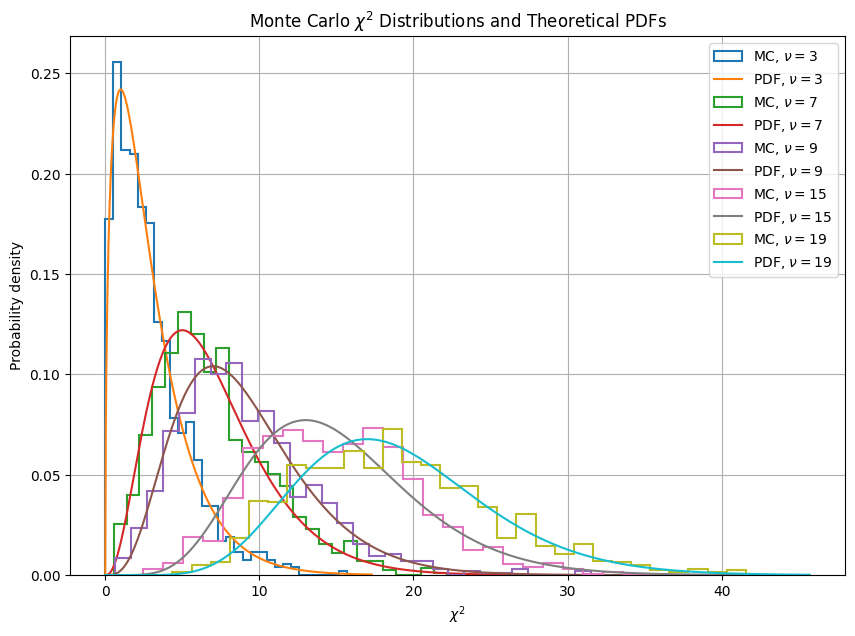

In [12]:
plt.figure(figsize=(10, 7))

for ndof in ndofs:

    values = chi2_samples[ndof]

    x_pdf = np.linspace(
        0,
        max(values) * 1.1,
        500
    )

    plt.hist(
        values,
        bins=30,
        density=True,
        histtype='step',
        linewidth=1.5,
        label=fr'MC, $\nu={ndof}$'
    )

    plt.plot(
        x_pdf,
        chi2.pdf(x_pdf, ndof),
        linewidth=1.5,
        label=fr'PDF, $\nu={ndof}$'
    )

plt.xlabel(r'$\chi^2$')
plt.ylabel('Probability density')
plt.title(r'Monte Carlo $\chi^2$ Distributions and Theoretical PDFs')
plt.legend()
plt.grid(True)

plt.show()

In [13]:
from scipy.stats import lognorm

In [14]:
Nexperiments = 1000

chi2_lognormal = {}

for ndof in ndofs:
    theory_n = theory[:ndof]
    sigma_n = sigma[:ndof]

    errors = lognorm.rvs(
        s=1,
        scale=1,
        size=(Nexperiments, ndof)
    )

    errors = (
        errors - np.mean(errors)
    ) / np.std(errors)

    measurements = theory_n + errors * sigma_n

    chi2_values = np.sum(
        ((measurements - theory_n) / sigma_n) ** 2,
        axis=1
    )

    chi2_lognormal[ndof] = chi2_values

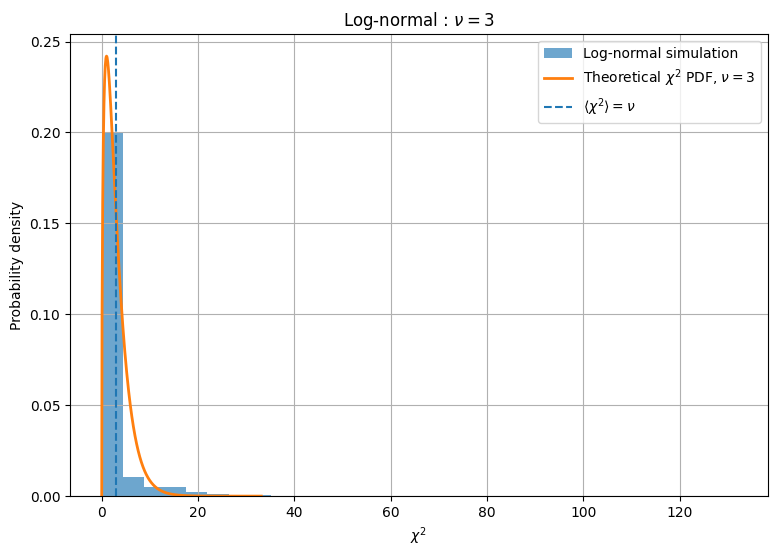

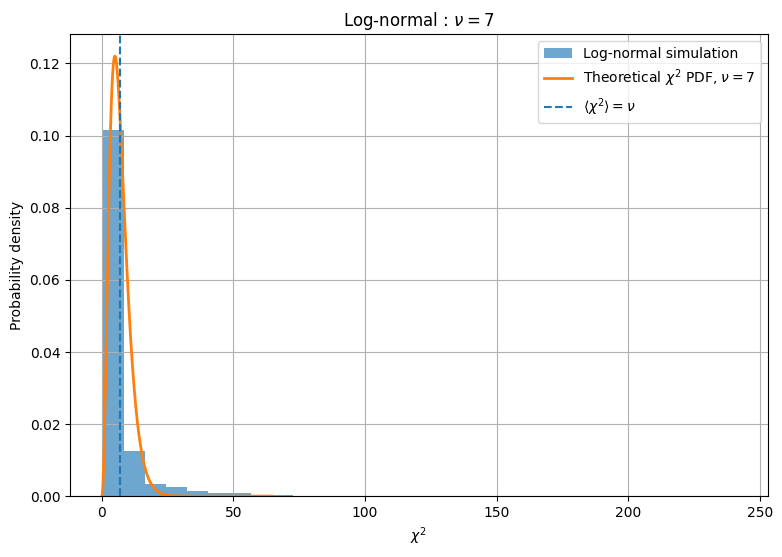

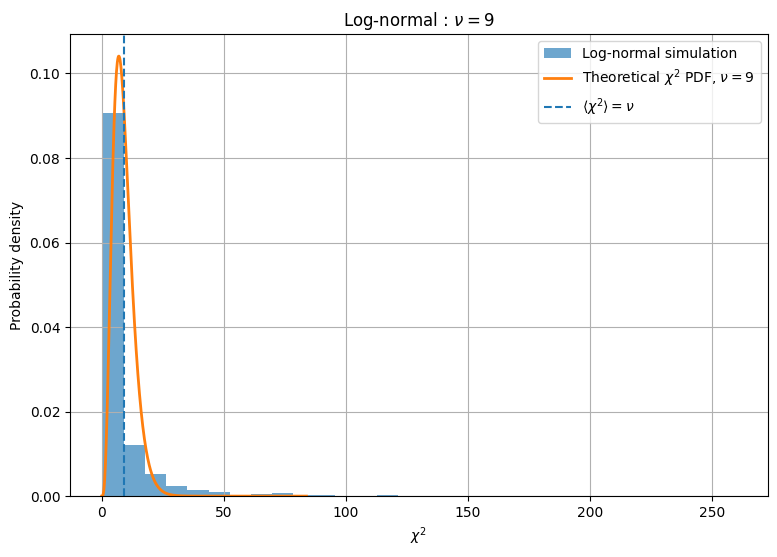

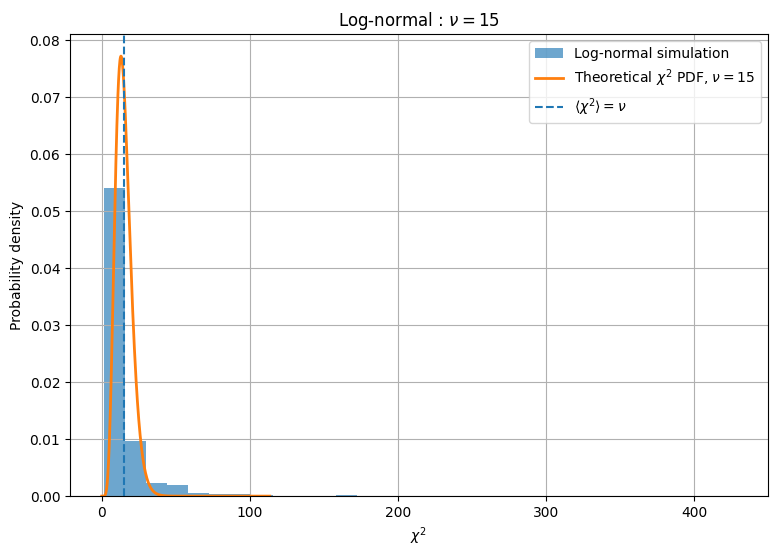

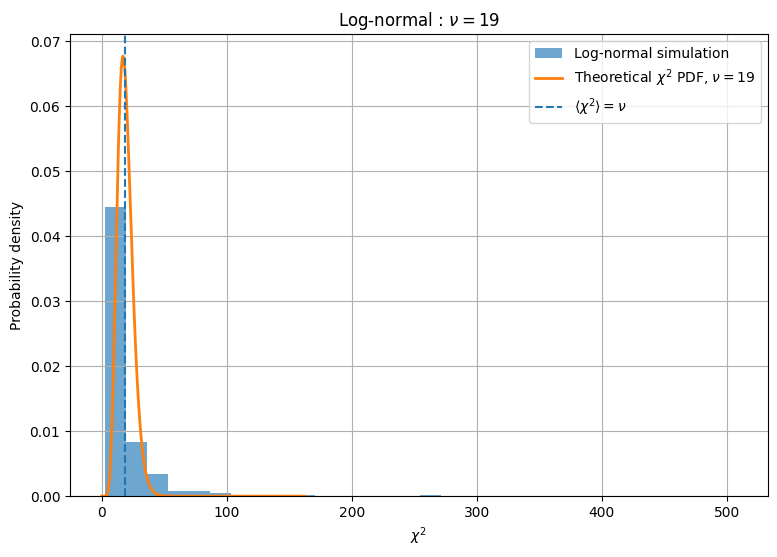

In [21]:
for ndof in ndofs:

    values = chi2_lognormal[ndof]

    plt.figure(figsize=(9, 6))

    plt.hist(
        values,
        bins=30,
        density=True,
        alpha=0.65,
        label='Log-normal simulation'
    )

    x_pdf = np.linspace(
        0,
        np.percentile(values, 99),
        500
    )

    plt.plot(
        x_pdf,
        chi2.pdf(x_pdf, ndof),
        linewidth=2,
        label=fr'Theoretical $\chi^2$ PDF, $\nu={ndof}$'
    )

    plt.axvline(
        ndof,
        linestyle='--',
        linewidth=1.5,
        label=r'$\langle\chi^2\rangle=\nu$'
    )

    plt.xlabel(r'$\chi^2$')
    plt.ylabel('Probability density')
    plt.title(
        rf'Log-normal : $\nu={ndof}$'
    )

    plt.legend()
    plt.grid(True)

    plt.show()

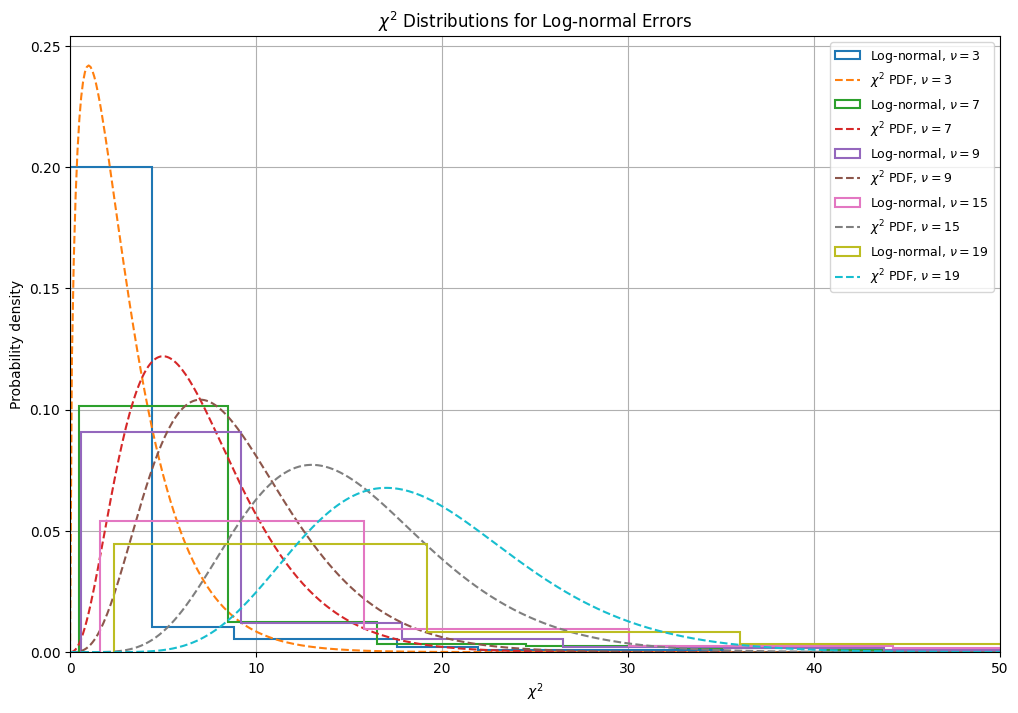

In [20]:
plt.figure(figsize=(12, 8))

for ndof in ndofs:

    values = chi2_lognormal[ndof]

    plt.hist(
        values,
        bins=30,
        density=True,
        histtype='step',
        linewidth=1.5,
        label=fr'Log-normal, $\nu={ndof}$'
    )

    x_pdf = np.linspace(0, 50, 500)

    plt.plot(
        x_pdf,
        chi2.pdf(x_pdf, ndof),
        linewidth=1.5,
        linestyle='--',
        label=fr'$\chi^2$ PDF, $\nu={ndof}$'
    )

plt.xlim(0, 50)

plt.xlabel(r'$\chi^2$')
plt.ylabel('Probability density')
plt.title(r'$\chi^2$ Distributions for Log-normal Errors')
plt.legend(fontsize=9)
plt.grid(True)

plt.show()